# 03.06 — Transfer Learning univariado: Austrália → Brasil e comparação com baselines

**Objetivo:** utilizar **somente potência brasileira** na entrada e nos alvos para treinamento/validação/teste, comparando modelos treinados do zero com o **previsor univariado** exportado pelo `03_05`. Não são carregados dados australianos — apenas os pesos pré-treinados em `pre_treinado_univariado_para_tl.pt`.

**Protocolo:** histórico de **240 horas** → previsão direta das **24 horas seguintes**; emissões horárias, sem atravessar lacunas, com partições cronológicas já definidas pelo `03_04`.

**Referências e escopo:** Ren et al. (2024), *A Novel Dual-Channel Temporal Convolutional Network for Photovoltaic Power Forecasting*, *Energies*, 17(3), 698, https://doi.org/10.3390/en17030698, com baselines **CNN** e **CNN-LSTM**. As implementações aqui são **versões univariadas adaptadas**, **não reproduções exatas** das redes ou dos resultados do artigo (outra resolução, janela e usina). Persistência 24h e TCN scratch são controles experimentais adicionais.

**Importante:** o checkpoint do `03_05` é a ramificação univariada treinada com **supervisão auxiliar conjunta**; **não** foi submetido a Knowledge Distillation. `source_only` mede o comportamento dessa ramificação sem ajuste brasileiro; `head` ajusta só a cabeça; `full` ajusta todo o modelo. Nenhum desses modelos recebe meteorologia como entrada.

## 1. Ambiente, caminhos e configuração

Para GPU: requer **PyTorch com CUDA**. O notebook utiliza a estrutura do projeto existente e falha explicitamente se faltarem os NPZ do `03_04` ou o checkpoint do `03_05`.

Para preservar o teste, mantenha `AVALIAR_TESTE_FINAL=False` enquanto escolher hiperparâmetros. Depois de congelar a metodologia, coloque `True` uma única vez para produzir a comparação final em dados não vistos.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import copy, hashlib, json, random, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

HISTORICO = 240
HORIZONTE = 24
SEEDS = [42]             # para réplica estatística, opcional: [42, 123, 2026]
BATCH_SIZE = 16          # RTX 3050 4GB: se OOM, tentar 8
MAX_EPOCAS = 50
PACIENCIA = 10
DELTA_HUBER = 0.05
WEIGHT_DECAY = 1e-4
LR_BASE = 1e-3
LR_ENCODER_TL = 1e-4
LR_CABECA_TL = 5e-4
AVALIAR_TESTE_FINAL = False
HORA_DIURNA_INICIO, HORA_DIURNA_FIM = 6, 18  # avaliação horária exploratória, não é irradiância medida
N_EXEMPLOS_GRAFICOS = 4

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.backends.cudnn.benchmark = True
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('ATENÇÃO: CUDA não detectado; treinamento em CPU.')

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/processed/sequencias_temporais_24h').is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError('Não localizei data/processed/sequencias_temporais_24h. Abra o notebook no projeto.')
TENSORES = RAIZ / 'data/processed/sequencias_temporais_24h'
DIR_PRETREINO = RAIZ / 'reports/tcc/03_05_pre_treinamento_dc_tcn' / f'L{HISTORICO}_H{HORIZONTE}_minmax_treino_seed42'
CHECKPOINT_AUSTRALIA = DIR_PRETREINO / 'pre_treinado_univariado_para_tl.pt'
# Se o 03_05 foi salvo em outra pasta, ajuste somente CHECKPOINT_AUSTRALIA.
if not CHECKPOINT_AUSTRALIA.is_file():
    raise FileNotFoundError(f'Checkpoint australiano ausente: {CHECKPOINT_AUSTRALIA}\n'
                            'Execute a exportação univariada no 03_05 ou ajuste CHECKPOINT_AUSTRALIA.')
SAIDA = RAIZ / 'reports/tcc/03_06_transfer_learning_brasil' / f'L{HISTORICO}_H{HORIZONTE}'
SAIDA.mkdir(parents=True, exist_ok=True)
print('Projeto:', RAIZ)
print('NPZ brasileiros:', TENSORES)
print('Pesos australianos:', CHECKPOINT_AUSTRALIA)
print('Saída:', SAIDA)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for bloco in iter(lambda: f.read(1024*1024), b''):
            h.update(bloco)
    return h.hexdigest()

def seed_tudo(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Projeto: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo
NPZ brasileiros: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\data\processed\sequencias_temporais_24h
Pesos australianos: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_05_pre_treinamento_dc_tcn\L240_H24_minmax_treino_seed42\pre_treinado_univariado_para_tl.pt
Saída: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_06_transfer_learning_brasil\L240_H24


## 2. Carregar os tensores brasileiros e ajustar Min–Max **apenas no treino**

Os NPZ do `03_04` já guardam `y_kw`, e `X_potencia` foi dividido por um fator numérico `capacidade_kw`. Aqui esse fator é utilizado **somente para desfazer a divisão antiga**: isso não presume nenhuma capacidade nominal real. O novo mínimo/máximo é calculado **exclusivamente** das potências de entrada e dos alvos do **treino brasileiro**. Validação e teste usam exatamente essa escala, sem reajuste/clipping do Min–Max.

Auditorias: janelas de 240 + 24 h consecutivas, timestamps, observação dos alvos, ausência de dados australianos e ordem cronológica.

In [2]:
PARTICOES = ('treino', 'validacao', 'teste')

def ler_npz_brasil(part):
    path = TENSORES / f'brasil_{part}_L{HISTORICO}_H{HORIZONTE}.npz'
    if not path.is_file():
        raise FileNotFoundError(f'NPZ não encontrado: {path}. Execute primeiro o 03_04.')
    with np.load(path, allow_pickle=False) as f:
        d = {k: f[k].copy() for k in f.files}
    campos = {'X', 'X_potencia', 'y', 'y_kw', 'capacidade_kw',
              'timestamps_X', 'timestamps_y', 'emissao', 'mask_y_observado', 'features'}
    if campos - d.keys(): raise ValueError(f'{path.name}: campos ausentes: {campos-d.keys()}')
    n = len(d['y'])
    if d['X_potencia'].shape != (n,HISTORICO,1) or d['y'].shape != (n,HORIZONTE):
        raise ValueError(f'{path.name}: formato de X_potencia/y inesperado')
    if d['X'].shape != (n,HISTORICO,1) or list(d['features']) != ['Active_Power']:
        raise ValueError(f'{path.name}: são esperados somente dados de potência brasileira')
    if d['y_kw'].shape != (n,HORIZONTE): raise ValueError('y_kw inconsistente')
    escala_antiga = float(d['capacidade_kw'])
    if not np.isfinite(escala_antiga) or escala_antiga <= 0: raise ValueError('Fator antigo inválido')
    if not np.allclose(d['X'][:,:,0], d['X_potencia'][:,:,0], atol=1e-6):
        raise ValueError('X e X_potencia incompatíveis')
    if not np.allclose(d['y']*escala_antiga, d['y_kw'], rtol=4e-5, atol=1e-3):
        raise ValueError('y_kw não corresponde ao fator de normalização anterior')
    if not np.isfinite(d['X_potencia']).all() or not np.isfinite(d['y_kw']).all():
        raise ValueError('Valores não finitos')
    if not np.all(d['mask_y_observado']): raise ValueError('Existem alvos não observados')
    if n:
        if not np.all(np.diff(d['timestamps_X'],axis=1) == np.timedelta64(1,'h')):
            raise ValueError('Lacunas no histórico')
        if not np.all(np.diff(d['timestamps_y'],axis=1) == np.timedelta64(1,'h')):
            raise ValueError('Lacunas no horizonte')
        if not np.all(d['timestamps_X'][:,-1] + np.timedelta64(1,'h') == d['emissao']):
            raise ValueError('Emissão diferente do fim do histórico')
        if not np.all(d['timestamps_y'][:,0] == d['emissao']):
            raise ValueError('Horizonte inicia fora da emissão')
    d['fator_antigo'] = escala_antiga
    d['arquivo'] = str(path)
    d['hash_sha256'] = sha256(path)
    return d

# O arquivo de TESTE é carregado apenas quando habilitado na seção final.
train_raw = ler_npz_brasil('treino')
val_raw = ler_npz_brasil('validacao')
if not len(train_raw['y']) or not len(val_raw['y']):
    raise ValueError('Treino e validação precisam ter amostras.')
if not train_raw['timestamps_y'].max() < val_raw['timestamps_y'].min():
    raise ValueError('Treino e validação não estão em ordem cronológica')

fator = train_raw['fator_antigo']
if fator != val_raw['fator_antigo']: raise ValueError('Fator antigo inconsistente')
MIN_BR = min(float(train_raw['X_potencia'].min()) * fator, float(train_raw['y_kw'].min()))
MAX_BR = max(float(train_raw['X_potencia'].max()) * fator, float(train_raw['y_kw'].max()))
AMP_BR = MAX_BR - MIN_BR
if not np.isfinite(AMP_BR) or AMP_BR <= 0: raise ValueError('Min–Max brasileiro inválido')

NORMALIZACAO_BR = {
    'metodo':'minmax_historico_e_alvos_treino_brasileiro',
    'min_kw':MIN_BR, 'max_kw':MAX_BR, 'amplitude_kw':AMP_BR,
    'fator_antigo_apenas_reversao_kw':fator,
    'clipping':False,
}

def transformar(raw):
    x_kw = raw['X_potencia'][:,:,0].astype(np.float64) * raw['fator_antigo']
    x = ((x_kw - MIN_BR)/AMP_BR).astype(np.float32)[:,:,None]
    y = ((raw['y_kw'].astype(np.float64) - MIN_BR)/AMP_BR).astype(np.float32)
    if not np.allclose(y.astype(np.float64)*AMP_BR+MIN_BR,raw['y_kw'],atol=1e-3,rtol=4e-5):
        raise ValueError('Inversão Min–Max falhou')
    return {'x':np.ascontiguousarray(x), 'y':np.ascontiguousarray(y),
            'y_kw':np.asarray(raw['y_kw'],dtype=np.float64),
            'emissao':raw['emissao'], 'timestamps_y':raw['timestamps_y']}

TREINO = transformar(train_raw)
VALIDACAO = transformar(val_raw)
print(f'Min–Max brasileiro do treino: [{MIN_BR:.4f}, {MAX_BR:.4f}] kW')
print('Treino:',TREINO['x'].shape,TREINO['y'].shape)
print('Validação:',VALIDACAO['x'].shape,VALIDACAO['y'].shape)
print('Faixa da validação (SEM clipping):',float(VALIDACAO['y'].min()),float(VALIDACAO['y'].max()))
print('Último alvo treino:', train_raw['timestamps_y'].max())
print('Primeiro alvo validação:', val_raw['timestamps_y'].min())
(SAIDA/'normalizacao_brasil.json').write_text(json.dumps(NORMALIZACAO_BR, indent=2, ensure_ascii=False),encoding='utf-8')

def montar_loader(dados, treino=False):
    ds = TensorDataset(torch.from_numpy(dados['x']),torch.from_numpy(dados['y']))
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=treino,num_workers=0,pin_memory=DEVICE.type=='cuda')

loader_treino = montar_loader(TREINO,True)
loader_validacao = montar_loader(VALIDACAO,False)

Min–Max brasileiro do treino: [0.0000, 1007.8729] kW
Treino: (1162, 240, 1) (1162, 24)
Validação: (395, 240, 1) (395, 24)
Faixa da validação (SEM clipping): 0.0 0.999708890914917
Último alvo treino: 2025-09-19T23:00:00.000000
Primeiro alvo validação: 2025-10-09T03:00:00.000000


## 3. Arquitetura **exata** da ramificação univariada salva no `03_05`

O código das classes `ConvCausal`, `BlocoTCN`, `EncoderTemporal` e `PrevisorUnivariado` foi trazido **sem modificar a estrutura e os nomes dos pesos**, de modo a carregar o `state_dict` integralmente com `strict=True`.

In [3]:
class ConvCausal(nn.Module):
    def __init__(self, canais, kernel, dilatacao):
        super().__init__()
        self.pad_esquerdo = (kernel - 1) * dilatacao
        self.conv = nn.Conv1d(canais, canais, kernel_size=kernel, dilation=dilatacao)
    def forward(self, x):
        return self.conv(F.pad(x, (self.pad_esquerdo, 0)))


class BlocoTCN(nn.Module):
    def __init__(self, canais, kernel, dilatacao, dropout):
        super().__init__()
        self.conv1 = ConvCausal(canais, kernel, dilatacao)
        self.conv2 = ConvCausal(canais, kernel, dilatacao)
        self.norm1 = nn.LayerNorm(canais)
        self.norm2 = nn.LayerNorm(canais)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: [B, C, T]. LayerNorm normaliza somente canais em cada instante.
        h = self.conv1(x).transpose(1, 2)
        h = self.dropout(F.gelu(self.norm1(h))).transpose(1, 2)
        h = self.conv2(h).transpose(1, 2)
        h = self.dropout(F.gelu(self.norm2(h))).transpose(1, 2)
        return x + h


class EncoderTemporal(nn.Module):
    def __init__(self, n_features, dim, n_blocos, kernel, dropout, usa_atencao=False, n_heads=4):
        super().__init__()
        self.proj = nn.Linear(n_features, dim)
        self.usa_atencao = usa_atencao
        if usa_atencao:
            self.atencao = nn.MultiheadAttention(dim, n_heads, dropout=dropout, batch_first=True)
            self.norm_att = nn.LayerNorm(dim)
        self.tcn = nn.Sequential(*[
            BlocoTCN(dim, kernel, 2**i, dropout) for i in range(n_blocos)
        ])

    def forward(self, x):
        # x: [B, T, features]; toda a janela é histórica e conhecida na emissão.
        x = self.proj(x)
        if self.usa_atencao:
            att, _ = self.atencao(x, x, x, need_weights=False)
            x = self.norm_att(x + att)
        z = self.tcn(x.transpose(1, 2)).transpose(1, 2)
        return z[:, -1, :]  # representação da última hora histórica


class PrevisorUnivariado(nn.Module):
    def __init__(self, dim, n_blocos, kernel, dropout, horizonte):
        super().__init__()
        self.encoder = EncoderTemporal(1, dim, n_blocos, kernel, dropout)
        self.cabeca = nn.Sequential(nn.Linear(dim, dim), nn.GELU(),
                                   nn.Dropout(dropout), nn.Linear(dim, horizonte))
    def forward(self, x_potencia):
        return self.cabeca(self.encoder(x_potencia))

In [4]:
# Só existe um checkpoint de origem: o student univariado do pré-treinamento australiano.
# Não importamos a ramificação multivariada nem qualquer tensor de meteorologia.
CKPT_AU = torch.load(CHECKPOINT_AUSTRALIA,map_location='cpu',weights_only=True)
if CKPT_AU.get('architecture') != 'PrevisorUnivariado':
    raise ValueError('Checkpoint incompatível com PrevisorUnivariado do 03_05')
CONF_AU = CKPT_AU['config']
if int(CONF_AU['hist']) != HISTORICO or int(CONF_AU['horizonte']) != HORIZONTE:
    raise ValueError('O checkpoint australiano exige L240_H24; use o 03_05 correspondente')

def montar_tcn():
    return PrevisorUnivariado(
        dim=int(CONF_AU['dim']), n_blocos=int(CONF_AU['blocks']),
        kernel=int(CONF_AU['kernel']), dropout=float(CONF_AU['dropout']),
        horizonte=HORIZONTE)

def tcn_australiana():
    m = montar_tcn()
    m.load_state_dict(CKPT_AU['model_state_dict'],strict=True)
    return m

m = tcn_australiana().to(DEVICE).eval()
with torch.no_grad():
    teste_saida = m(torch.tensor(TREINO['x'][:2],device=DEVICE))
assert teste_saida.shape == (2,HORIZONTE)
print('Checkpoint compatível, saída:', tuple(teste_saida.shape))
print('Parâmetros da TCN:',sum(p.numel() for p in m.parameters()))
del m

Checkpoint compatível, saída: (2, 24)
Parâmetros da TCN: 155608


## 4. Comparadores univariados: **CNN e CNN-LSTM** (Ren et al., 2024)

As implementações abaixo são **adaptadas** para potência isolada, janelas L240/H24 e mesma disponibilidade brasileira. Não reproduzem exatamente a Figura 7 do artigo. A persistência de 24 horas é um baseline operacional adicional.

In [5]:
class CNNUnivariada(nn.Module):
    def __init__(self, horizonte=24, dropout=0.1):
        super().__init__()
        self.features=nn.Sequential(
            nn.Conv1d(1,32,5,padding=2),nn.GELU(),
            nn.Conv1d(32,64,5,padding=2),nn.GELU(),
            nn.Conv1d(64,64,3,padding=1),nn.GELU(),
            nn.Dropout(dropout),
        )
        self.cabeca=nn.Sequential(nn.Linear(128,64),nn.GELU(),nn.Dropout(dropout),nn.Linear(64,horizonte))
    def forward(self,x):
        z=self.features(x.transpose(1,2))
        z=torch.cat((z.mean(dim=-1),z[:,:,-1]),dim=1)
        return self.cabeca(z)

class CNNLSTMUnivariada(nn.Module):
    def __init__(self, horizonte=24, dropout=0.1):
        super().__init__()
        self.conv=nn.Sequential(nn.Conv1d(1,32,5,padding=2),nn.GELU(),
                                nn.Conv1d(32,32,3,padding=1),nn.GELU())
        self.lstm=nn.LSTM(input_size=32,hidden_size=64,num_layers=1,batch_first=True)
        self.cabeca=nn.Sequential(nn.Dropout(dropout),nn.Linear(64,horizonte))
    def forward(self,x):
        z=self.conv(x.transpose(1,2)).transpose(1,2)
        z,_=self.lstm(z)
        return self.cabeca(z[:,-1,:])

@torch.no_grad()
def persistencia_24(dados):
    if dados['x'].shape[1] < 24: raise ValueError('Histórico insuficiente para persistência de 24 horas')
    # A hora h futura é prevista com a mesma hora do dia anterior (últimas 24h do histórico).
    return dados['x'][:,-24:,0].copy()

for cls in [CNNUnivariada,CNNLSTMUnivariada]:
    m=cls().to(DEVICE)
    with torch.no_grad(): teste=m(torch.tensor(TREINO['x'][:2],device=DEVICE))
    assert tuple(teste.shape)==(2,HORIZONTE)
    print(cls.__name__,'OK, parâmetros:',sum(p.numel() for p in m.parameters()))
    del m

CNNUnivariada OK, parâmetros: 32664
CNNLSTMUnivariada OK, parâmetros: 29944


## 5. Treinamento controlado e seleção **somente pela validação brasileira**

Condições avaliadas:

| Nome | Inicialização | Atualização no Brasil |
|---|---|---|
| Persistencia_24h | Sem rede | Sem treinamento |
| CNN_scratch | Aleatória | Toda a CNN |
| CNN_LSTM_scratch | Aleatória | CNN + LSTM |
| TCN_scratch | Aleatória | Toda a TCN |
| TCN_source_only | Pesos da Austrália | Sem treinamento |
| TCN_TL_head | Pesos da Austrália | Apenas cabeça de regressão |
| TCN_TL_full | Pesos da Austrália | Encoder e cabeça (LR menor no encoder) |

A TCN scratch e as duas TCNs transferidas possuem **arquitetura idêntica**. Todos os métodos usam a mesma normalização e as mesmas janelas brasileiras. Os checkpoints são escolhidos pelo menor MAE de validação, não pelo teste.

In [6]:
criterio = nn.HuberLoss(delta=DELTA_HUBER)
MODELOS = ['Persistencia_24h','CNN_scratch','CNN_LSTM_scratch','TCN_scratch',
           'TCN_source_only','TCN_TL_head','TCN_TL_full']

def criar_modelo(nome):
    if nome=='CNN_scratch':
        m=CNNUnivariada()
    elif nome=='CNN_LSTM_scratch':
        m=CNNLSTMUnivariada()
    elif nome=='TCN_scratch':
        m=montar_tcn()
    elif nome in ('TCN_source_only','TCN_TL_head','TCN_TL_full'):
        m=tcn_australiana()
    else:
        raise ValueError(nome)
    if nome=='TCN_TL_head':
        for p in m.encoder.parameters(): p.requires_grad_(False)
    return m.to(DEVICE)

def criar_otimizador(modelo,nome):
    if nome=='TCN_TL_full':
        return torch.optim.AdamW([
            {'params':modelo.encoder.parameters(),'lr':LR_ENCODER_TL},
            {'params':modelo.cabeca.parameters(),'lr':LR_CABECA_TL},
        ],weight_decay=WEIGHT_DECAY)
    return torch.optim.AdamW([p for p in modelo.parameters() if p.requires_grad],
                             lr=LR_BASE,weight_decay=WEIGHT_DECAY)

@torch.no_grad()
def previsoes_modelo(modelo,dados):
    modelo.eval()
    loader=montar_loader(dados,False)
    pred=[]
    for x,_ in loader:
        yhat=modelo(x.to(DEVICE,non_blocking=True))
        pred.append(yhat.cpu().numpy())
    return np.concatenate(pred,axis=0)

@torch.no_grad()
def mae_validacao(modelo,dados):
    modelo.eval()
    erro,n=0.0,0
    for x,y in montar_loader(dados,False):
        x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
        out=modelo(x)
        # MESMA métrica para seleção em todos os modelos: MAE normalizado sem clipping.
        erro+=torch.abs(out-y).sum().item()
        n+=y.numel()
    return erro/n

def uma_epoca(modelo,opt):
    modelo.train()
    # Congela também comportamento de treinamento do encoder (sem dropout) no TL_head.
    if not any(p.requires_grad for p in modelo.encoder.parameters()) if hasattr(modelo,'encoder') else False:
        modelo.encoder.eval()
    total,n=0.0,0
    for x,y in loader_treino:
        x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
        opt.zero_grad(set_to_none=True)
        out=modelo(x)
        loss=criterio(out,y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_([p for p in modelo.parameters() if p.requires_grad],1.0)
        opt.step()
        total+=loss.item()*len(y)
        n+=len(y)
    return total/max(n,1)

historicos=[]
modelos_salvos={}
metricas_val=[]
previsoes_val={}

# A semente é fixada antes da criação de CADA modelo, evitando variações acidentais.
for seed in SEEDS:
    for nome in MODELOS:
        slug=f'{nome}_seed{seed}'
        if nome=='Persistencia_24h':
            pred=persistencia_24(VALIDACAO)
            previsoes_val[slug]=pred
            continue
        seed_tudo(seed)
        modelo=criar_modelo(nome)
        arquivo=SAIDA/f'best_{slug}.pt'
        if nome=='TCN_source_only':
            torch.save({'model_state_dict':modelo.cpu().state_dict(), 'modelo':nome,
                        'seed':seed,'normalizacao_brasil':NORMALIZACAO_BR,
                        'origem_checkpoint':str(CHECKPOINT_AUSTRALIA)},arquivo)
            modelo=modelo.to(DEVICE)
            val_mae=mae_validacao(modelo,VALIDACAO)
            print(f'{slug} | source-only (sem ajuste) | MAE val norm={val_mae:.5f}')
        else:
            opt=criar_otimizador(modelo,nome)
            scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=0.5,patience=4)
            melhor=float('inf'); sem_melhora=0
            inicio=time.perf_counter()
            for ep in range(1,MAX_EPOCAS+1):
                loss_t=uma_epoca(modelo,opt)
                val_mae=mae_validacao(modelo,VALIDACAO)
                scheduler.step(val_mae)
                historicos.append({'modelo':nome,'seed':seed,'epoca':ep,
                                   'loss_treino':loss_t,'mae_val_normalizado':val_mae,
                                   'lr':opt.param_groups[0]['lr']})
                if val_mae<melhor-1e-7:
                    melhor=val_mae; melhor_ep=ep; sem_melhora=0
                    torch.save({'model_state_dict':copy.deepcopy(modelo.state_dict()),
                                'modelo':nome,'seed':seed,'epoca':ep,
                                'mae_val_normalizado':melhor,'normalizacao_brasil':NORMALIZACAO_BR,
                                'origem_checkpoint':str(CHECKPOINT_AUSTRALIA) if nome.startswith('TCN_TL') else None},arquivo)
                else:
                    sem_melhora+=1
                if ep==1 or ep%5==0 or sem_melhora>=PACIENCIA:
                    print(f'{slug} | ep {ep:03d} | loss={loss_t:.5f} | val MAE={val_mae:.5f} | sem melhora={sem_melhora}')
                if sem_melhora>=PACIENCIA: break
            print(f'{slug}: melhor época={melhor_ep} MAE val={melhor:.5f} | {time.perf_counter()-inicio:.0f}s')
            salvo=torch.load(arquivo,map_location=DEVICE,weights_only=True)
            modelo.load_state_dict(salvo['model_state_dict'],strict=True)
        previsoes_val[slug]=previsoes_modelo(modelo,VALIDACAO)
        modelos_salvos[slug]=str(arquivo)
        del modelo
        if DEVICE.type=='cuda': torch.cuda.empty_cache()

pd.DataFrame(historicos).to_csv(SAIDA/'historicos_treinamento.csv',index=False)
print('Finalizado treinamento. Nenhuma métrica do teste foi usada.')

CNN_scratch_seed42 | ep 001 | loss=0.01029 | val MAE=0.16961 | sem melhora=0
CNN_scratch_seed42 | ep 005 | loss=0.00483 | val MAE=0.10925 | sem melhora=0
CNN_scratch_seed42 | ep 010 | loss=0.00432 | val MAE=0.10604 | sem melhora=2
CNN_scratch_seed42 | ep 015 | loss=0.00416 | val MAE=0.09824 | sem melhora=0
CNN_scratch_seed42 | ep 020 | loss=0.00395 | val MAE=0.10062 | sem melhora=5
CNN_scratch_seed42 | ep 025 | loss=0.00376 | val MAE=0.09983 | sem melhora=2
CNN_scratch_seed42 | ep 030 | loss=0.00366 | val MAE=0.09485 | sem melhora=0
CNN_scratch_seed42 | ep 035 | loss=0.00360 | val MAE=0.09737 | sem melhora=5
CNN_scratch_seed42 | ep 040 | loss=0.00354 | val MAE=0.09591 | sem melhora=2
CNN_scratch_seed42 | ep 045 | loss=0.00354 | val MAE=0.09481 | sem melhora=7
CNN_scratch_seed42 | ep 048 | loss=0.00354 | val MAE=0.09537 | sem melhora=10
CNN_scratch_seed42: melhor época=38 MAE val=0.09420 | 46s
CNN_LSTM_scratch_seed42 | ep 001 | loss=0.00910 | val MAE=0.13038 | sem melhora=0
CNN_LSTM_scr

## 6. Comparação na validação brasileira e análise por horizonte

Métricas na escala **kW**, calculadas após desfazer o Min–Max brasileiro. Predições negativas são truncadas em zero **somente na avaliação**, para todos os métodos, pela restrição física de potência não negativa. Não há clipping de valores superiores ao máximo histórico.

A métrica diurna considera horas civis **06:00–17:59** dos timestamps do `03_04` (recorte aproximado, não posição solar). As 24 previsões de uma mesma janela e as janelas deslizantes sobrepostas **não são observações independentes**.

VALIDAÇÃO brasileira (não é o teste final)


,modelo,seed,n_janelas,mae_kw,rmse_kw,r2,bias_kw,mae_diurno_kw,rmse_diurno_kw,wape_diurno_pct
0,CNN_LSTM_scratch,42,395,68.8534,131.1180,0.8175,23.3814,133.9242,185.3121,29.6051
1,TCN_TL_full,42,395,69.0594,132.1501,0.8146,23.2868,134.2639,186.7639,29.6802
2,TCN_scratch,42,395,69.6731,130.8284,0.8183,10.8937,136.2561,184.9402,30.1206
3,TCN_TL_head,42,395,71.4421,134.1517,0.8090,15.6990,137.7720,189.4783,30.4557
4,TCN_source_only,42,395,76.6986,142.2587,0.7852,28.6844,148.9171,200.9059,32.9195
5,Persistencia_24h,42,395,83.6242,164.8649,0.7115,-8.7026,166.9044,233.1517,36.8957
6,CNN_scratch,42,395,92.5530,162.5136,0.7197,11.1187,171.4692,224.2252,37.9048


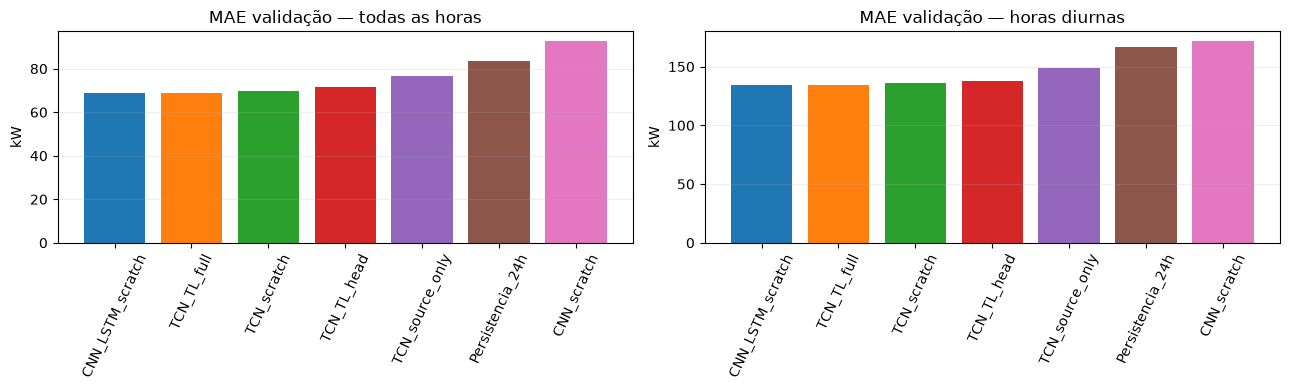

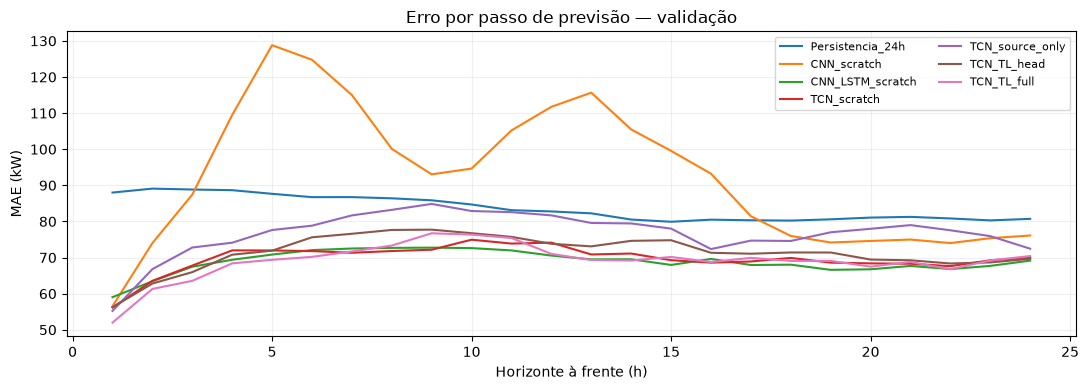

In [7]:
def desnormalizar(pred):
    return np.asarray(pred,dtype=np.float64)*AMP_BR+MIN_BR

def metricas(dados,pred_normalizado,modelo,seed):
    y=dados['y_kw'].astype(np.float64)
    pred=np.maximum(0.0,desnormalizar(pred_normalizado))
    if pred.shape!=y.shape: raise ValueError('Previsão com forma errada')
    erro=pred-y
    horas=pd.to_datetime(dados['timestamps_y'].reshape(-1)).hour.to_numpy().reshape(y.shape)
    mask_diurna=(horas>=HORA_DIURNA_INICIO)&(horas<HORA_DIURNA_FIM)
    def obter(a,b):
        e=b-a
        return (float(np.abs(e).mean()),float(np.sqrt(np.square(e).mean())))
    mae,rmse=obter(y,pred)
    mae_d,rmse_d=obter(y[mask_diurna],pred[mask_diurna]) if mask_diurna.any() else (np.nan,np.nan)
    v_y=np.square(y-y.mean()).sum()
    r2=float(1-np.square(erro).sum()/v_y) if v_y>1e-12 else np.nan
    # WAPE calculado nas horas diurnas para não confundir com MAPE em y=0.
    den=np.abs(y[mask_diurna]).sum()
    wape_d=float(np.abs(erro[mask_diurna]).sum()/den*100) if den>1e-8 else np.nan
    return {'modelo':modelo,'seed':seed,'n_janelas':len(y),'mae_kw':mae,'rmse_kw':rmse,
            'r2':r2,'bias_kw':float(erro.mean()),'mae_diurno_kw':mae_d,
            'rmse_diurno_kw':rmse_d,'wape_diurno_pct':wape_d}

def comparar_conjunto(dados,previsoes,nome):
    rows=[]; horizons=[]
    for key, pred in previsoes.items():
        modelo,seed=key.rsplit('_seed',1)
        rows.append(metricas(dados,pred,modelo,int(seed)))
        y=dados['y_kw']; p=np.maximum(0.,desnormalizar(pred))
        for h in range(HORIZONTE):
            e=p[:,h]-y[:,h]
            horizons.append({'modelo':modelo,'seed':int(seed),'horizonte_h':h+1,
                             'mae_kw':float(np.abs(e).mean()),'rmse_kw':float(np.sqrt(np.square(e).mean()))})
    tabela=pd.DataFrame(rows).sort_values(['mae_kw','modelo']).reset_index(drop=True)
    tabela.to_csv(SAIDA/f'metricas_{nome}.csv',index=False)
    pd.DataFrame(horizons).to_csv(SAIDA/f'erro_horizontes_{nome}.csv',index=False)
    display(tabela.round(4))
    return tabela,pd.DataFrame(horizons)

print('VALIDAÇÃO brasileira (não é o teste final)')
tabela_val,hor_val=comparar_conjunto(VALIDACAO,previsoes_val,'validacao')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for nome, g in tabela_val.groupby('modelo',sort=False):
    axes[0].bar(nome,g.mae_kw.mean())
    axes[1].bar(nome,g.mae_diurno_kw.mean())
axes[0].set_title('MAE validação — todas as horas')
axes[1].set_title('MAE validação — horas diurnas')
for ax in axes: ax.set_ylabel('kW'); ax.tick_params(axis='x',rotation=65); ax.grid(axis='y',alpha=0.2)
plt.tight_layout()
plt.savefig(SAIDA/'comparacao_validacao.png',dpi=170,bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(11,4))
for nome,g in hor_val.groupby('modelo',sort=False):
    ax.plot(g.groupby('horizonte_h').mae_kw.mean().index,
            g.groupby('horizonte_h').mae_kw.mean().values,label=nome)
ax.set(xlabel='Horizonte à frente (h)',ylabel='MAE (kW)',title='Erro por passo de previsão — validação')
ax.grid(alpha=.2); ax.legend(ncol=2,fontsize=8)
plt.tight_layout(); plt.savefig(SAIDA/'mae_por_horizonte_validacao.png',dpi=170); plt.show()

## 7. Diagnóstico gráfico de previsões brasileiras na validação

Os exemplos abaixo são escolhidos por posições determinadas no conjunto de validação, **não** por menor erro. Exibem saídas de 24 horas para persistência, TCN scratch, TCN full TL e CNN-LSTM. Os resultados reais só aparecem ao executar com os NPZ brasileiros.

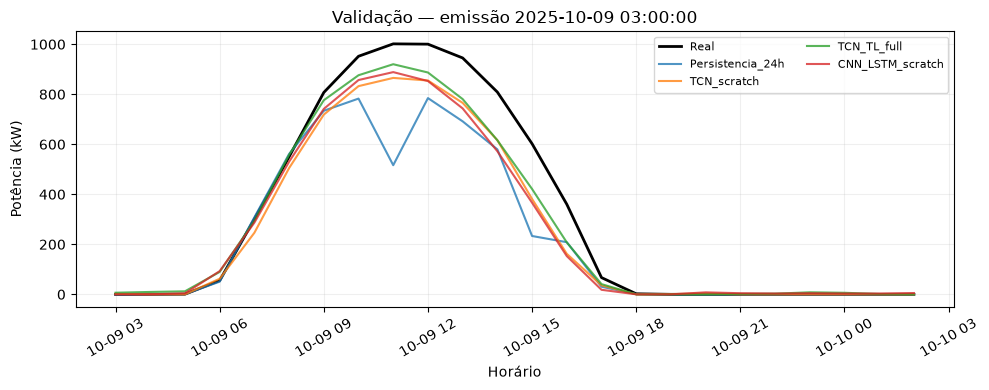

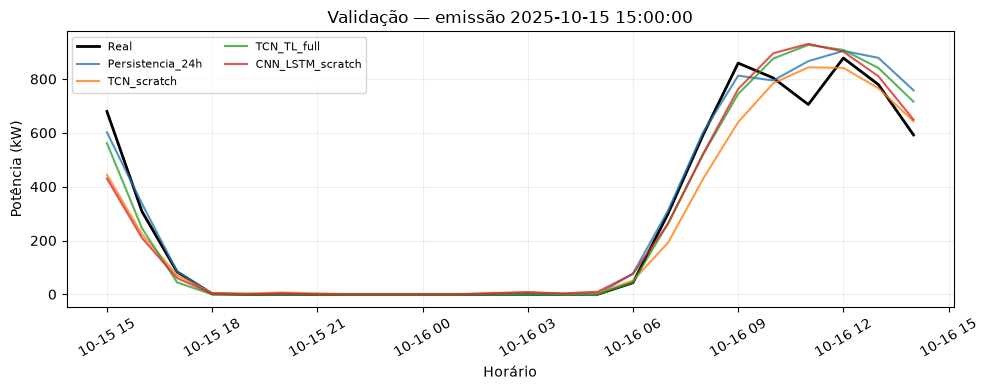

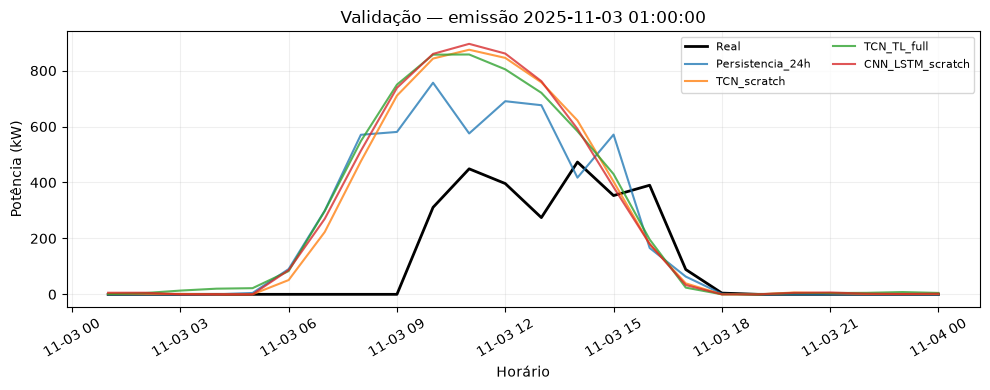

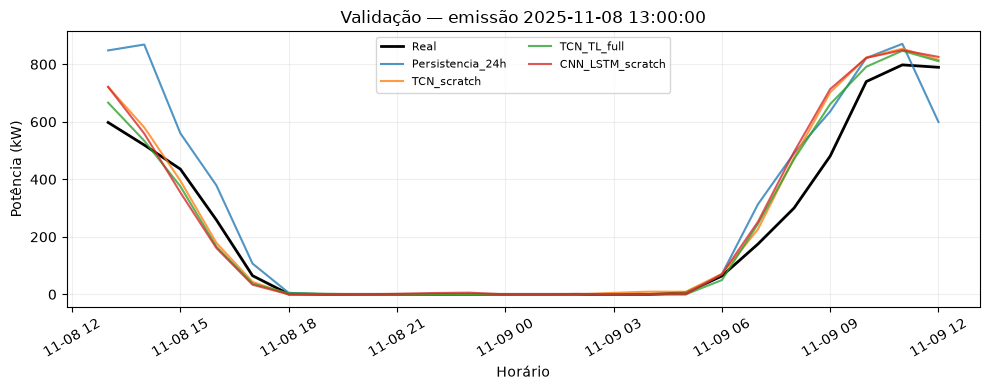

In [8]:
mostrar=['Persistencia_24h','TCN_scratch','TCN_TL_full','CNN_LSTM_scratch']
indices=np.linspace(0,len(VALIDACAO['y'])-1,num=min(N_EXEMPLOS_GRAFICOS,len(VALIDACAO['y'])),dtype=int)
for idx in indices:
    fig,ax=plt.subplots(figsize=(10,4))
    t=pd.to_datetime(VALIDACAO['timestamps_y'][idx])
    ax.plot(t,VALIDACAO['y_kw'][idx],label='Real',color='black',lw=2)
    for nome in mostrar:
        key=f'{nome}_seed{SEEDS[0]}'
        ax.plot(t,np.maximum(0,desnormalizar(previsoes_val[key])[idx]),label=nome,alpha=.78)
    ax.set(title=f'Validação — emissão {pd.Timestamp(VALIDACAO["emissao"][idx])}',ylabel='Potência (kW)',xlabel='Horário')
    ax.grid(alpha=.2);ax.legend(ncol=2,fontsize=8)
    plt.xticks(rotation=30);plt.tight_layout()
    plt.savefig(SAIDA/f'exemplo_val_{idx:04d}.png',dpi=160,bbox_inches='tight');plt.show()

## 8. TESTE brasileiro final — executar uma única vez após fixar o protocolo

Para evitar ajuste indireto ao conjunto de teste, a célula abaixo só o carrega quando `AVALIAR_TESTE_FINAL=True`. A seleção de **todos** os checkpoints foi feita pela validação brasileira, antes de abrir o teste.

As métricas das janelas horárias sobrepostas podem superestimar a precisão estatística; além da tabela geral, a célula calcula uma **subamostra ilustrativa de emissões espaçadas por pelo menos 24 horas**, sem considerá-la independente em sentido estrito. Se poucas emissões restarem, isso será informado no relatório.

In [9]:
if not AVALIAR_TESTE_FINAL:
    print('Teste preservado. Quando encerrar as escolhas metodológicas, defina AVALIAR_TESTE_FINAL=True e execute esta célula.')
else:
    teste_raw=ler_npz_brasil('teste')
    if not val_raw['timestamps_y'].max() < teste_raw['timestamps_y'].min():
        raise ValueError('Partições de validação/teste não estão em ordem cronológica')
    TESTE=transformar(teste_raw)
    previsoes_teste={}
    for seed in SEEDS:
        for nome in MODELOS:
            key=f'{nome}_seed{seed}'
            if nome=='Persistencia_24h':
                previsoes_teste[key]=persistencia_24(TESTE)
                continue
            modelo=criar_modelo(nome)
            ck=torch.load(modelos_salvos[key],map_location=DEVICE,weights_only=True)
            modelo.load_state_dict(ck['model_state_dict'],strict=True)
            previsoes_teste[key]=previsoes_modelo(modelo,TESTE)
            del modelo
            if DEVICE.type=='cuda': torch.cuda.empty_cache()
    print('TESTE brasileiro final — todas as emissões')
    tabela_teste,hor_teste=comparar_conjunto(TESTE,previsoes_teste,'teste')
    print('Variação percentual do MAE frente à TCN scratch (mesma semente)')
    ganhos=[]
    for seed in SEEDS:
        controle=tabela_teste.query('modelo == "TCN_scratch" and seed == @seed').iloc[0]['mae_kw']
        for _,linha in tabela_teste.query('seed == @seed').iterrows():
            ganhos.append({'modelo':linha['modelo'],'seed':seed,
                           'ganho_mae_vs_tcn_scratch_pct':100*(1-linha['mae_kw']/controle)})
    display(pd.DataFrame(ganhos).round(3))
    pd.DataFrame(ganhos).to_csv(SAIDA/'ganhos_transfer_learning_teste.csv',index=False)
    # Selecionar emissões com >=24h de distância; não reconstrói janelas, só reduz sobreposição de alvos.
    emis=pd.to_datetime(TESTE['emissao'])
    escolhidos=[];ultima=None
    for i,t in enumerate(emis):
        if ultima is None or t-ultima>=pd.Timedelta(hours=24):
            escolhidos.append(i); ultima=t
    print(f'Subamostra de emissões separadas por >=24h: {len(escolhidos)} / {len(emis)}')
    if escolhidos:
        fatia={k:(v[escolhidos] if isinstance(v,np.ndarray) and len(v)==len(emis) else v) for k,v in TESTE.items()}
        pre={k:v[escolhidos] for k,v in previsoes_teste.items()}
        print('Teste — emissões espaçadas')
        comparar_conjunto(fatia,pre,'teste_emissoes_espacadas')
    fig,ax=plt.subplots(figsize=(10,4))
    for nome,g in hor_teste.groupby('modelo'):
        ax.plot(g.groupby('horizonte_h').mae_kw.mean().index,
                g.groupby('horizonte_h').mae_kw.mean().values,label=nome)
    ax.set(xlabel='Horizonte à frente (h)',ylabel='MAE (kW)',title='Teste brasileiro — MAE por horizonte')
    ax.legend(ncol=2,fontsize=8);ax.grid(alpha=.2);plt.tight_layout()
    plt.savefig(SAIDA/'mae_por_horizonte_teste.png',dpi=170);plt.show()
    print('Resultado final salvo em:',SAIDA)

Teste preservado. Quando encerrar as escolhas metodológicas, defina AVALIAR_TESTE_FINAL=True e execute esta célula.


## 9. Manifesto do experimento e checklist metodológico

Os dados de entrada são sempre brasileiros: **não** há `X` multivariado, irradiância ou variáveis meteorológicas no `03_06`. O checkpoint australiano é usado **exclusivamente como inicialização de parâmetros**. Os modelos comparadores CNN/CNN-LSTM seguem as **famílias** empregadas por Ren et al. (2024), mas não suas métricas originais. Para comparar com números do artigo, seriam necessários igualar usina, datas, resolução, pré-processamento e arquitetura.

**Limitações:** amostras de previsão horária sobrepostas, disponibilidade limitada de dados brasileiros e cobertura sazonal parcial. Para conclusão estatística, repetir com múltiplas seeds e, quando disponível, ampliar as usinas/datas. Se escolher o melhor hiperparâmetro após examinar o teste, o teste deixa de ser independente.

In [10]:
manifesto={
    'estudo':'03_06 Transfer Learning univariado AU→BR',
    'timestamp_utc':datetime.now(timezone.utc).isoformat(),
    'historico_h':HISTORICO,'horizonte_h':HORIZONTE,
    'seeds':SEEDS,'modelos':MODELOS,
    'normalizacao_brasileira':NORMALIZACAO_BR,
    'checkpoint_australia':str(CHECKPOINT_AUSTRALIA),
    'checkpoint_au_sha256':sha256(CHECKPOINT_AUSTRALIA),
    'npz_brasil_treino':train_raw['arquivo'], 'npz_brasil_treino_sha256':train_raw['hash_sha256'],
    'npz_brasil_validacao':val_raw['arquivo'], 'npz_brasil_validacao_sha256':val_raw['hash_sha256'],
    'npz_teste_lido':bool(AVALIAR_TESTE_FINAL),
    'config_treinamento':{'max_epocas':MAX_EPOCAS,'paciencia':PACIENCIA,'batch':BATCH_SIZE,
                          'lr_base':LR_BASE,'lr_encoder_tl':LR_ENCODER_TL,'lr_cabeca_tl':LR_CABECA_TL,
                          'loss':'Huber','delta':DELTA_HUBER},
    'torch':torch.__version__,'python':sys.version.split()[0],
    'comparadores_artigo':['CNN','CNN-LSTM'],
    'referencia':'https://doi.org/10.3390/en17030698',
}
(SAIDA/'manifesto_03_06.json').write_text(json.dumps(manifesto,ensure_ascii=False,indent=2),encoding='utf-8')
print('Arquivos na saída:')
for p in sorted(SAIDA.iterdir()): print(' -',p.name)

Arquivos na saída:
 - best_CNN_LSTM_scratch_seed42.pt
 - best_CNN_scratch_seed42.pt
 - best_TCN_scratch_seed42.pt
 - best_TCN_source_only_seed42.pt
 - best_TCN_TL_full_seed42.pt
 - best_TCN_TL_head_seed42.pt
 - comparacao_validacao.png
 - erro_horizontes_validacao.csv
 - exemplo_val_0000.png
 - exemplo_val_0131.png
 - exemplo_val_0262.png
 - exemplo_val_0394.png
 - historicos_treinamento.csv
 - mae_por_horizonte_validacao.png
 - manifesto_03_06.json
 - metricas_validacao.csv
 - normalizacao_brasil.json
